In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics

In [2]:
df = pd.read_csv('C:/Users/guilherme_doge1/Desktop/Ciência de Dados/Aula 13 - 09-11-2026/producao_automatizada_5000.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Sensores_Automacao     5000 non-null   float64
 1   Robotica_Atuadores     5000 non-null   float64
 2   Manutencao_Preventiva  5000 non-null   float64
 3   Volume_Produzido       5000 non-null   float64
dtypes: float64(4)
memory usage: 156.4 KB


In [4]:
display(df.head())

,Sensores_Automacao,Robotica_Atuadores,Manutencao_Preventiva,Volume_Produzido
0,124.9,22.7,43.6,20.9
1,286.2,26.3,40.0,26.5
2,225.0,43.5,25.9,21.7
3,187.6,20.3,64.7,22.2
4,63.7,44.1,52.9,15.0


In [5]:
display(df.corr())

,Sensores_Automacao,Robotica_Atuadores,Manutencao_Preventiva,Volume_Produzido
Sensores_Automacao,1.000000,-0.007048,-0.009482,0.800866
Robotica_Atuadores,-0.007048,1.000000,-0.022862,0.242636
Manutencao_Preventiva,-0.009482,-0.022862,1.000000,0.330669
Volume_Produzido,0.800866,0.242636,0.330669,1.000000


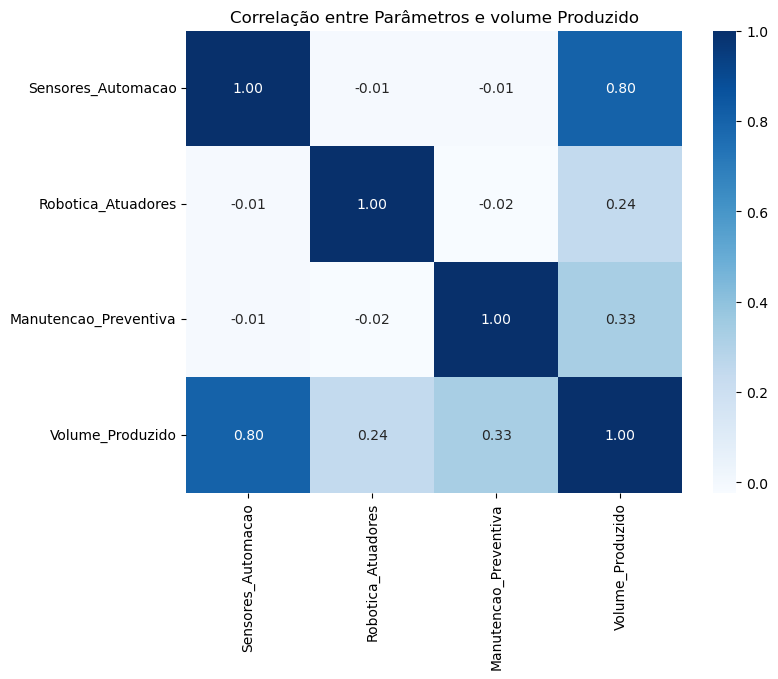

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlação entre Parâmetros e volume Produzido')
plt.show()

In [7]:
x = df[['Sensores_Automacao', 'Robotica_Atuadores', 'Manutencao_Preventiva']]
y = df['Volume_Produzido']

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2, random_state=42)

In [8]:
modelo_regressao_linear = LinearRegression()
modelo_arvore_regressora = RandomForestRegressor(random_state=42)

In [9]:
modelo_regressao_linear.fit(x_treino, y_treino)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [10]:
modelo_arvore_regressora.fit(x_treino, y_treino)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [11]:
previsao_regressao_linear = modelo_regressao_linear.predict(x_teste)
previsao_arvore_regressora = modelo_arvore_regressora.predict(x_teste)

In [12]:
print(f'Regressão Linear: {metrics.r2_score(y_teste, previsao_regressao_linear):.2%}')

Regressão Linear: 83.08%


In [13]:
print(f'Random Forest: {metrics.r2_score(y_teste, previsao_arvore_regressora):.2%}')

Random Forest: 81.05%


In [14]:
novos_investimentos = pd.DataFrame({
    'Sensores_Automacao': [150.0, 250.0, 50.0],
    'Robotica_Atuadores': [30.0, 45.0, 10.0],
    'Manutencao_Preventiva': [40.0, 60.0, 15.0]
})

previsoes_novos_cenarios = modelo_regressao_linear.predict(novos_investimentos)
novos_investimentos['Volume_Produzido_Previsto (Milhões)'] = previsoes_novos_cenarios

display(novos_investimentos)

,Sensores_Automacao,Robotica_Atuadores,Manutencao_Preventiva,Volume_Produzido_Previsto (Milhões)
0,150.0,30.0,40.0,18.856023
1,250.0,45.0,60.0,28.118558
2,50.0,10.0,15.0,8.605806
